In [2]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd

capital = 100000
tickers = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN']
w = np.ones(len(tickers)) / len(tickers)

prices = yf.download(tickers, start='2023-11-02', end='2026-11-02')['Close']
forex = yf.download('USDMXN=X', start='2023-11-02', end='2026-11-02')['Close']
prices.loc[pd.Timestamp('2026-11-02'), 'BIMBOA.MX'] = 66.18
prices.loc[pd.Timestamp('2026-11-02'), 'NVDA'] = 202.60
prices.loc[pd.Timestamp('2026-11-02'), 'CEMEXCPO.MX'] = 20.23
prices.loc[pd.Timestamp('2026-11-02'), 'AZN'] = 186.58
forex.loc[pd.Timestamp('2026-11-02')] = 18.58

C:\Users\1\AppData\Local\Temp\ipykernel_36904\186096221.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start='2023-11-02', end='2026-11-02')['Close']
[*********************100%***********************]  4 of 4 completed
C:\Users\1\AppData\Local\Temp\ipykernel_36904\186096221.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  forex = yf.download('USDMXN=X', start='2023-11-02', end='2026-11-02')['Close']
[*********************100%***********************]  1 of 1 completed


In [151]:
def final_price(S0, mean, std, T, sims):
    return S0 * np.exp((mean - 0.5 * std**2) * T + std * np.sqrt(T) * np.random.normal(size=sims))

## Forex

In [152]:
forex_returns = np.log(forex / forex.shift(1)).dropna()
mean_forex = forex_returns.mean()*252
std_forex = forex_returns.std()*np.sqrt(252)
S0_forex = forex.loc[pd.Timestamp('2026-11-02')].values[0]

st_forex_dis = final_price(S0_forex, mean_forex.values[0], std_forex.values[0], 1, 1000)
st_forex = np.mean(st_forex_dis)
print(f"Cambio hoy USD/MXN: {S0_forex:.2f}")
print(f"Cambio Esperado USD/MXN en 2027: {st_forex:.2f}")

Cambio hoy USD/MXN: 18.58
Cambio Esperado USD/MXN en 2027: 18.84


## A. Solo NVDA

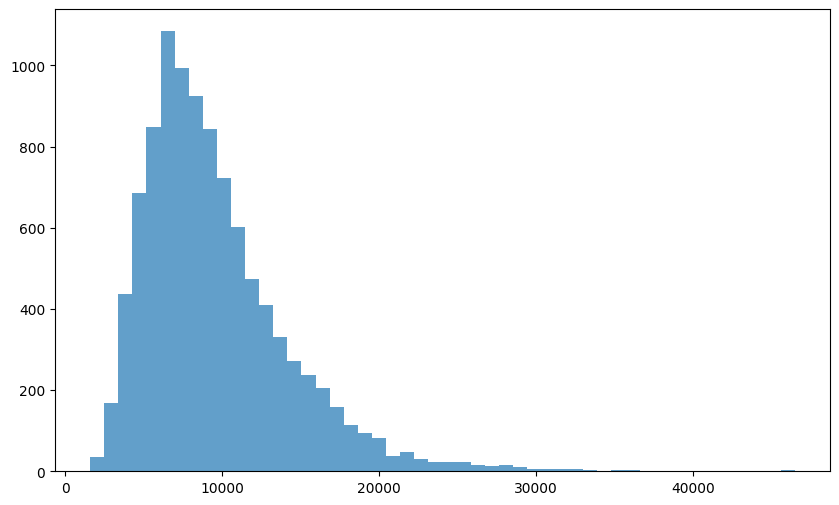

Valor del portafolio actual: 100000.00 MXN
Valor del portafolio en 2027: 180363.54 MXN
Rendimiento Portafolio: 80.36%


In [153]:
np.random.seed(67)
prices_nvda = prices['NVDA']
lg_rets = np.log(prices_nvda / prices_nvda.shift(1)).dropna()
mean = lg_rets.mean()*252
std = lg_rets.std()*np.sqrt(252)

cap_dollars = capital / S0_forex
w = 1
v0 = cap_dollars * w
S0 = prices_nvda.iloc[-1]
N0 = np.floor(v0 / S0)
T = 1



st_dis = final_price(S0, mean, std, T, 10000)
vt_dis = st_dis * N0
vt = np.mean(vt_dis) * st_forex

plt.figure(figsize=(10, 6))
plt.hist(vt_dis, bins=50, alpha=0.7)
plt.show()
print(f'Valor del portafolio actual: {capital:.2f} MXN')
print(f'Valor del portafolio en 2027: {vt:.2f} MXN')
print(f'Rendimiento Portafolio: {(vt - capital) / capital * 100:.2f}%')


## B. Portafolio Equiponderado

In [155]:
lg_rets = np.log(prices / prices.shift(1)).dropna()
mean = lg_rets.mean()*252
std = lg_rets.std()*np.sqrt(252)
w = [0.25, 0.25, 0.25, 0.25]
v0 = np.sum(capital*w)
S0 = prices.iloc[-1]
S0[['AZN','NVDA']] = S0[['AZN','NVDA']]*st_forex
N0 = np.floor(v0/S0)
T = 1
final_prices = []
for ticker in tickers:
    S0 = S0[ticker]
    lg_rets = lg_rets[ticker]
    mean = lg_rets.mean()*252
    std = lg_rets.std()*np.sqrt(252)
    st_dis = final_price(S0, mean, std, T, 1000)
    final_prices.append(st_dis)


vt_dis = st_dis * N0
vt = np.mean(vt_dis) * st_forex

plt.figure(figsize=(10, 6))
plt.hist(vt_dis, bins=50, alpha=0.7)
plt.show()

print(f'Valor del portafolio actual: {capital:.2f} MXN')
print(f'Valor del portafolio en 2027: {vt:.2f} MXN')
print(f'Rendimiento Portafolio: {(vt - capital) / capital * 100:.2f}%')

C:\Users\1\AppData\Local\Temp\ipykernel_1960\2592588752.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  S0[['AZN','NVDA']] = S0[['AZN','NVDA']]*st_forex
C:\Users\1\AppData\Local\Temp\ipykernel_1960\2592588752.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  S0[['AZN','NVDA']] = S0[['AZN','NVDA']]*st_forex


IndexError: invalid index to scalar variable.

Index(['AZN', 'BIMBOA.MX', 'CEMEXCPO.MX', 'NVDA'], dtype='object', name='Ticker')

## C. Portafolio de Pesos Crecientes

--- 

## Calculo de parámetros para la simulación multiactivo
A partir de la matriz de covaraianza de mis activos calculamos con Cholesky la discomposición de la matriz de covarianza en sus matrices diagonales así mismo calculamos nuestra distribución multinomial con media 0 y varianzas independientes. Con esto podemos ajustar nuestros universos de Z en una matrz de activos X universos.

In [12]:
ticker = ['AAPL', 'MSFT', 'NVDA']
prices = yf.download(ticker, start='2023-11-04', end = '2026-11-04')['Close']
rets = np.log(prices / prices.shift(1)).dropna()

M = 10000
n_act = len(ticker)
cov  = rets.cov()

L = np.linalg.cholesky(cov)
E = np.random.normal(0,1, size=(n_act, M))
Z = L @ E
Z = Z.T


C:\Users\1\AppData\Local\Temp\ipykernel_36904\4052156074.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start='2023-11-04', end = '2026-11-04')['Close']
[*********************100%***********************]  3 of 3 completed


## GBM usando nuestra variable estocástica nueva

Dado a que tenemos nuestros universos calculamos por medio de GBM el precio final en 1 año iterando en nuestra matriz de Z.

In [13]:
T = 1
ST = np.zeros(shape=(M, n_act))
cont = 0
for ticker in prices.columns:
    S0 = prices[ticker].iloc[-1]
    mu = rets[ticker].mean()*252
    vol = rets[ticker].std()*np.sqrt(252)
    st = S0*np.exp(mu-0.5*(vol**2)*T + vol*np.sqrt(T)*Z[:, cont])
    ST[:, cont] = st
    cont += 1

ST

array([[395.51931004, 577.54437226, 309.20041897],
       [396.30365389, 577.6175977 , 311.17652993],
       [394.01404851, 579.07249353, 308.07192892],
       ...,
       [396.50864257, 577.96172228, 311.93954336],
       [397.75895794, 572.18570833, 308.76899312],
       [392.71710638, 572.5357502 , 300.1616355 ]], shape=(10000, 3))